# 1.2 Distribution of Variables and Statistics

**Merged version** (MIZ + Jaden + VZH) — section 1.2 only.

Contents:
- 1.2.1 Summary of statistics
- 1.2.2 Distribution via histograms
- 1.2.3 Distribution via pie chart
- 1.2.4 Distribution via bar chart


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

df = pd.read_csv('dataset/seller_info_dm1_2627.csv')

TARGET = 'seller_rating_class'
ID_COLUMN = 'sp_id'
RATING_ORDER = ['low', 'medium', 'high']

# Basic integrity checks
assert df[ID_COLUMN].notna().all()
assert df[ID_COLUMN].is_unique
assert df[TARGET].isin(RATING_ORDER).all()

numeric_columns = df.select_dtypes(include=[np.number]).columns.drop(ID_COLUMN).tolist()
categorical_cols = df.select_dtypes(include='str').columns.tolist()

print('All records:', len(df))
print('Numeric columns:', len(numeric_columns))
print('Categorical columns:', len(categorical_cols))


All records: 13843
Numeric columns: 24
Categorical columns: 8


### 1.2.1 Summary of statistics


                     count  percent
seller_rating_class                
low                   2579    18.63
medium                7577    54.74
high                  3687    26.63


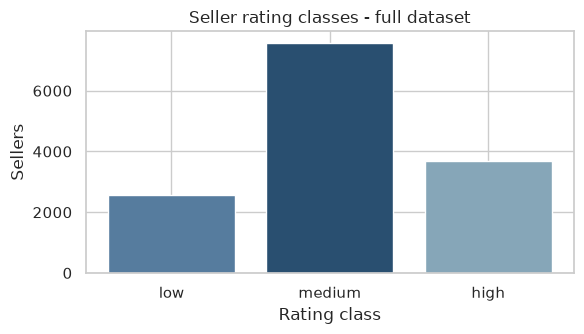

In [13]:
# Target class distribution on the full dataset
target_summary = df[TARGET].value_counts().reindex(RATING_ORDER).to_frame('count')
target_summary['percent'] = (target_summary['count'] / len(df) * 100).round(2)
print(target_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(target_summary.index, target_summary['count'], color=['#567c9e', '#294f70', '#86a6b8'])
ax.set(title='Seller rating classes - full dataset', xlabel='Rating class', ylabel='Sellers')
fig.tight_layout()
plt.show()


In [14]:
# Numeric summary with missingness, skewness, kurtosis and IQR
stats_df = df[numeric_columns].describe().T
stats_df['missing'] = df[numeric_columns].isna().sum()
stats_df['skew'] = df[numeric_columns].skew()
stats_df['kurtosis'] = df[numeric_columns].kurtosis()
stats_df['iqr'] = stats_df['75%'] - stats_df['25%']

stats_df.round(2)


,count,mean,std,min,25%,50%,75%,max,missing,skew,kurtosis,iqr
n_listings,13843.0,118.10,137.06,5.00,25.00,70.00,168.00,4959.00,0,5.25,120.32,143.00
price_median,13843.0,23106.14,14365.07,1699.00,12495.00,22385.00,29888.00,236438.00,0,3.45,34.14,17393.00
savings_amount_median,13843.0,446.21,519.46,0.00,0.00,358.00,734.00,9333.00,0,2.40,18.30,734.00
daysonmarket_median,13843.0,49.15,56.06,0.00,26.00,36.00,51.00,1987.00,0,8.75,168.60,25.00
mileage_median,13842.0,51463.27,51845.46,0.00,25.00,33596.50,96915.75,238541.00,1,0.68,-0.77,96890.75
year_median,13843.0,2015.95,4.72,1960.00,2013.00,2017.00,2020.00,2021.00,0,-2.25,14.09,7.00
vehicle_age_median,13842.0,4.08,4.63,0.00,0.00,3.00,7.00,60.00,1,2.32,14.98,7.00
owner_count_median,13804.0,1.43,0.62,1.00,1.00,1.00,2.00,6.00,39,1.30,1.35,1.00
horsepower_median,13837.0,240.90,56.99,78.00,188.00,243.00,283.00,630.00,6,0.85,2.05,95.00
engine_displacement_median,10450.0,2925.08,808.08,1200.00,2400.00,2500.00,3500.00,6800.00,3393,1.29,2.77,1100.00


In [15]:
stats_df[['min', 'max']]

,min,max
n_listings,5.00,4959.000000
price_median,1699.00,236438.000000
savings_amount_median,0.00,9333.000000
daysonmarket_median,0.00,1987.000000
mileage_median,0.00,238541.000000
year_median,1960.00,2021.000000
vehicle_age_median,0.00,60.000000
owner_count_median,1.00,6.000000
horsepower_median,78.00,630.000000
engine_displacement_median,1200.00,6800.000000


In [16]:
# Categorical summary: levels, missing entries, and literal "unknown" labels
categorical_summary = pd.DataFrame({
    'observed_categories': df[categorical_cols].nunique(),
    'missing': df[categorical_cols].isna().sum(),
    'literal_unknown': df[categorical_cols].eq('unknown').sum(),
})
categorical_summary


,observed_categories,missing,literal_unknown
dominant_body_type,9,0,0
dominant_fuel_type,7,0,1
dominant_transmission,4,0,6
dominant_wheel_system,5,10518,0
dominant_listing_color,11,0,1510
franchise_status,2,0,0
new_used_profile,3,0,0
seller_rating_class,3,0,0


#### Key insights (1.2.1)

- **Class imbalance**: medium 54.7%, high 26.6%, low 18.6% → use a majority-class baseline
  and, later in classification, a stratified split and Macro-F1.
- **No constant variables**, but `pct_salvage` and `pct_theft_title` are **zero-inflated**
  (25/50/75% = 0) with extreme right skew (10.3 / 14.1): most sellers are clean-title,
  a small niche specialises in salvage/theft vehicles.
- **Severe scale disparity**: `pct_*` ∈ [0, 1] and legroom varies by < 1 in, whereas
  `mileage_median` spans 0–238k and `price_median` 1.7k–236k → motivates scaling (§1.4).
- **Missingness is concentrated**: `dominant_wheel_system` 76.0%, `engine_displacement_median`
  24.5%; all other columns < 0.3%.
- **Literal `unknown` ≠ missing**: for example, `dominant_listing_color` has 1,510 explicit
  `unknown` labels that are distinct from empty CSV entries.


### 1.2.2 Distribution via histograms


**Variable selection for the plots.** The histograms show a manually selected
subset (12 of the 24 numeric features) that covers the main semantic dimensions without
near-duplicates: seller size (`n_listings`), price (`price_median`), time on market
(`daysonmarket_median`), usage (`mileage_median`), age (`year_median`), ownership
(`owner_count_median`), performance (`horsepower_median`), efficiency
(`city_fuel_economy_median`), cabin (`front_legroom_median`), capacity
(`fuel_tank_volume_median`), exterior size (`height_median`), and new-inventory share
(`pct_is_new`). Near-duplicate features (age, highway fuel, rear legroom, length/width)
are omitted; the full set remains in the summary table and the notebook.


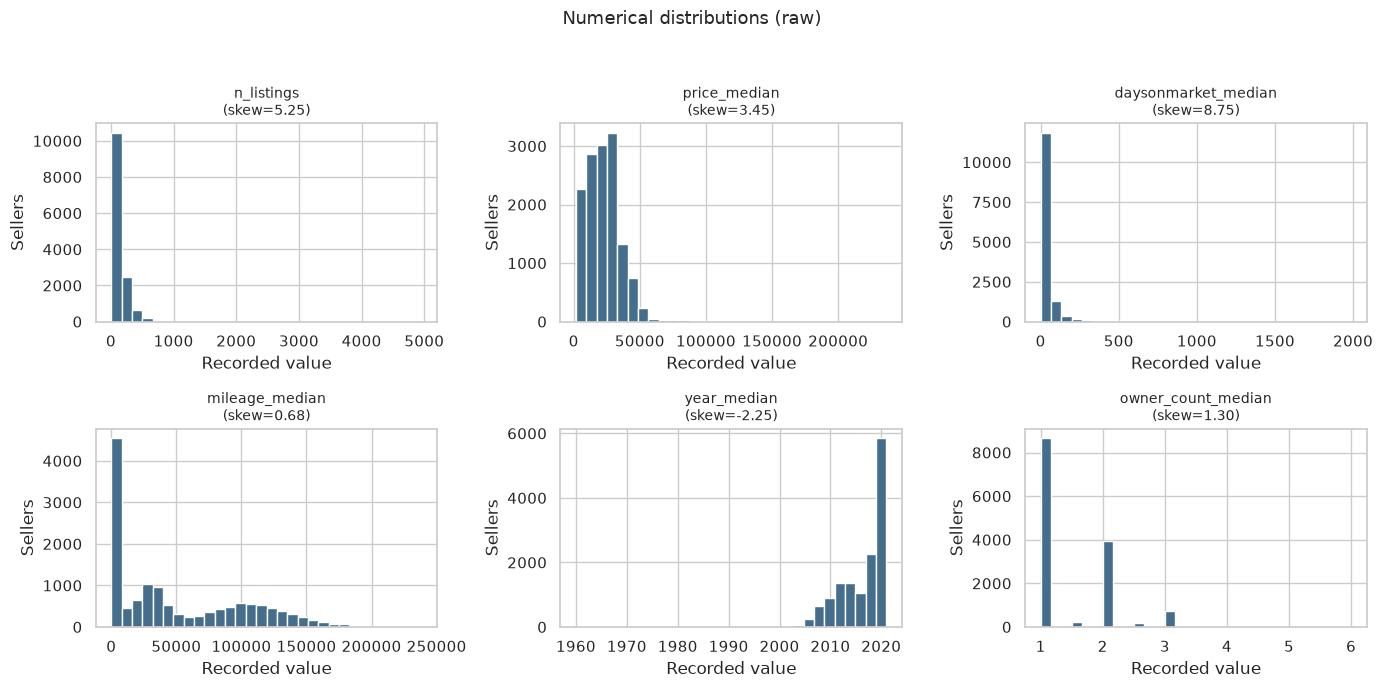

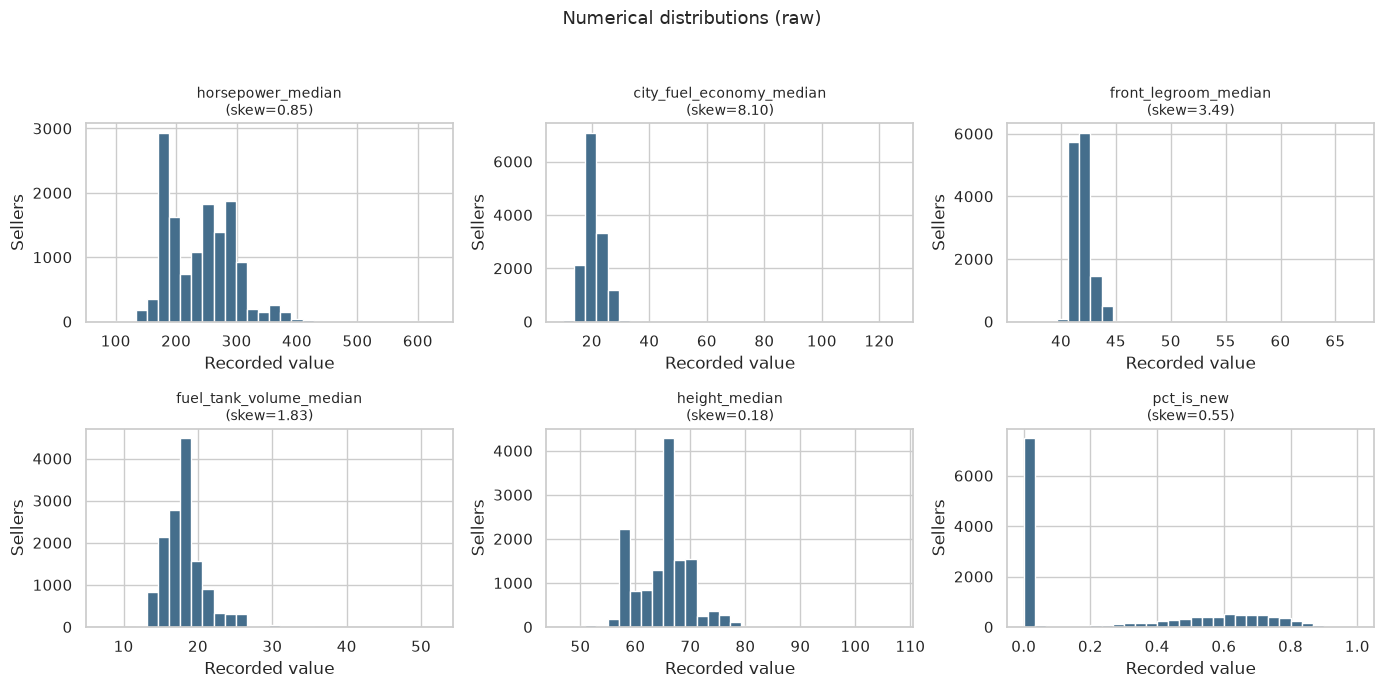

In [17]:
selected_numeric = [
    'n_listings',
    'price_median',
    'daysonmarket_median',
    'mileage_median',
    'year_median',
    'owner_count_median',
    'horsepower_median',
    'city_fuel_economy_median',
    'front_legroom_median',
    'fuel_tank_volume_median',
    'height_median',
    'pct_is_new',
]

# Histograms in chunks of six for readability (skewness annotated)
for start in range(0, len(selected_numeric), 6):
    columns = selected_numeric[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, column in zip(axes.ravel(), columns):
        ax.hist(df[column].dropna(), bins=30, color='#456e8c', edgecolor='white')
        ax.set_title(f'{column}\n(skew={df[column].skew():.2f})', fontsize=10)
        ax.set_xlabel('Recorded value')
        ax.set_ylabel('Sellers')
    for ax in axes.ravel()[len(columns):]:
        ax.set_visible(False)
    fig.suptitle('Numerical distributions (raw)', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


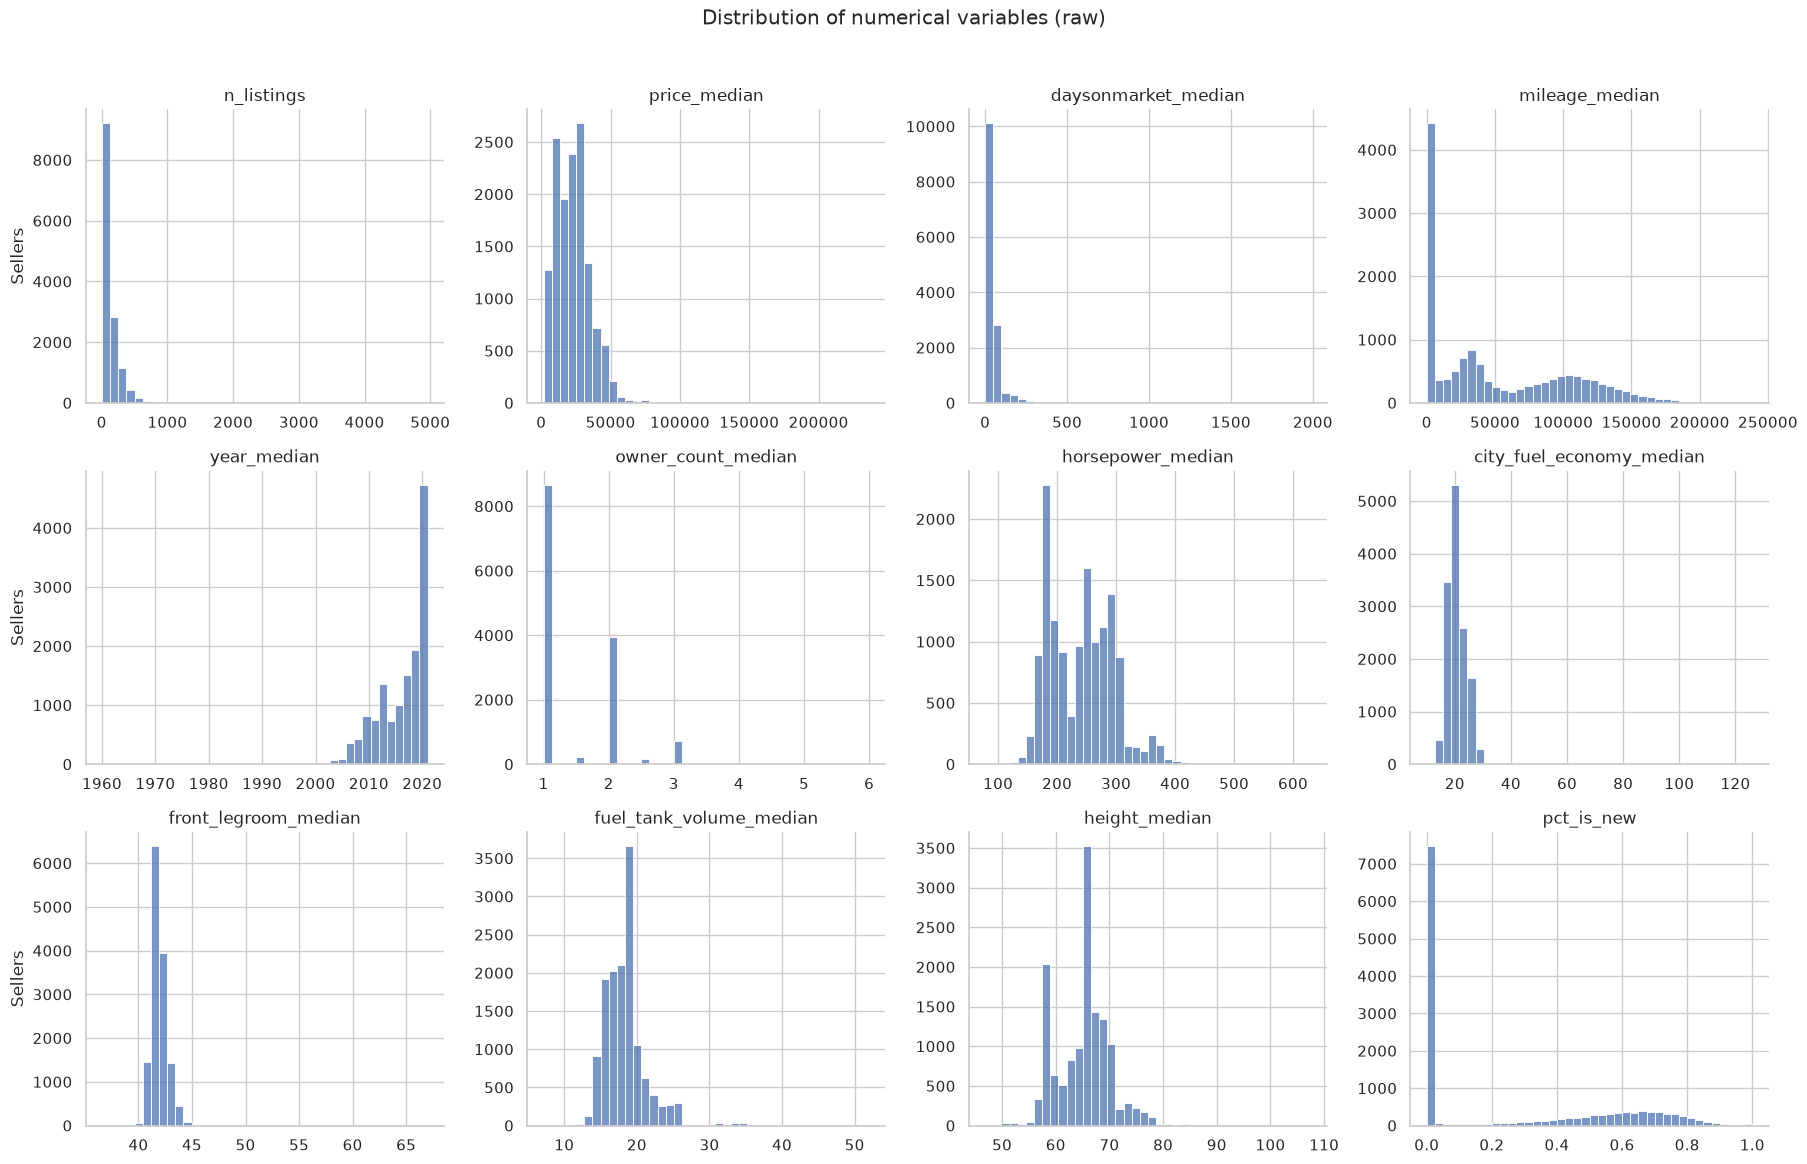

In [18]:
# Same distributions as a facet grid (one panel per variable)
plot_df = df[selected_numeric].melt(var_name='variable', value_name='value')

g = sns.FacetGrid(
    plot_df, col='variable', col_wrap=4,
    sharex=False, sharey=False, height=3.8, aspect=1.2,
)
g.map_dataframe(sns.histplot, x='value', bins=40)

# "value" comes from melt(); the panel title already names the variable.
g.set_axis_labels('', 'Sellers')
g.set_titles('{col_name}')
g.figure.suptitle('Distribution of numerical variables (raw)', y=1.02)
plt.tight_layout()
plt.show()


/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(*plot_args, **plot_kwargs)
/mnt/SPANTIUM/01_Academic/S2 - UniPi/Semesters/Semester1/Data Mining/code/data-mining_unipi_1_2026/.venv/lib64/python3.14/site-packages/seaborn/axisgrid.py:854: UserWarning: Ignoring `

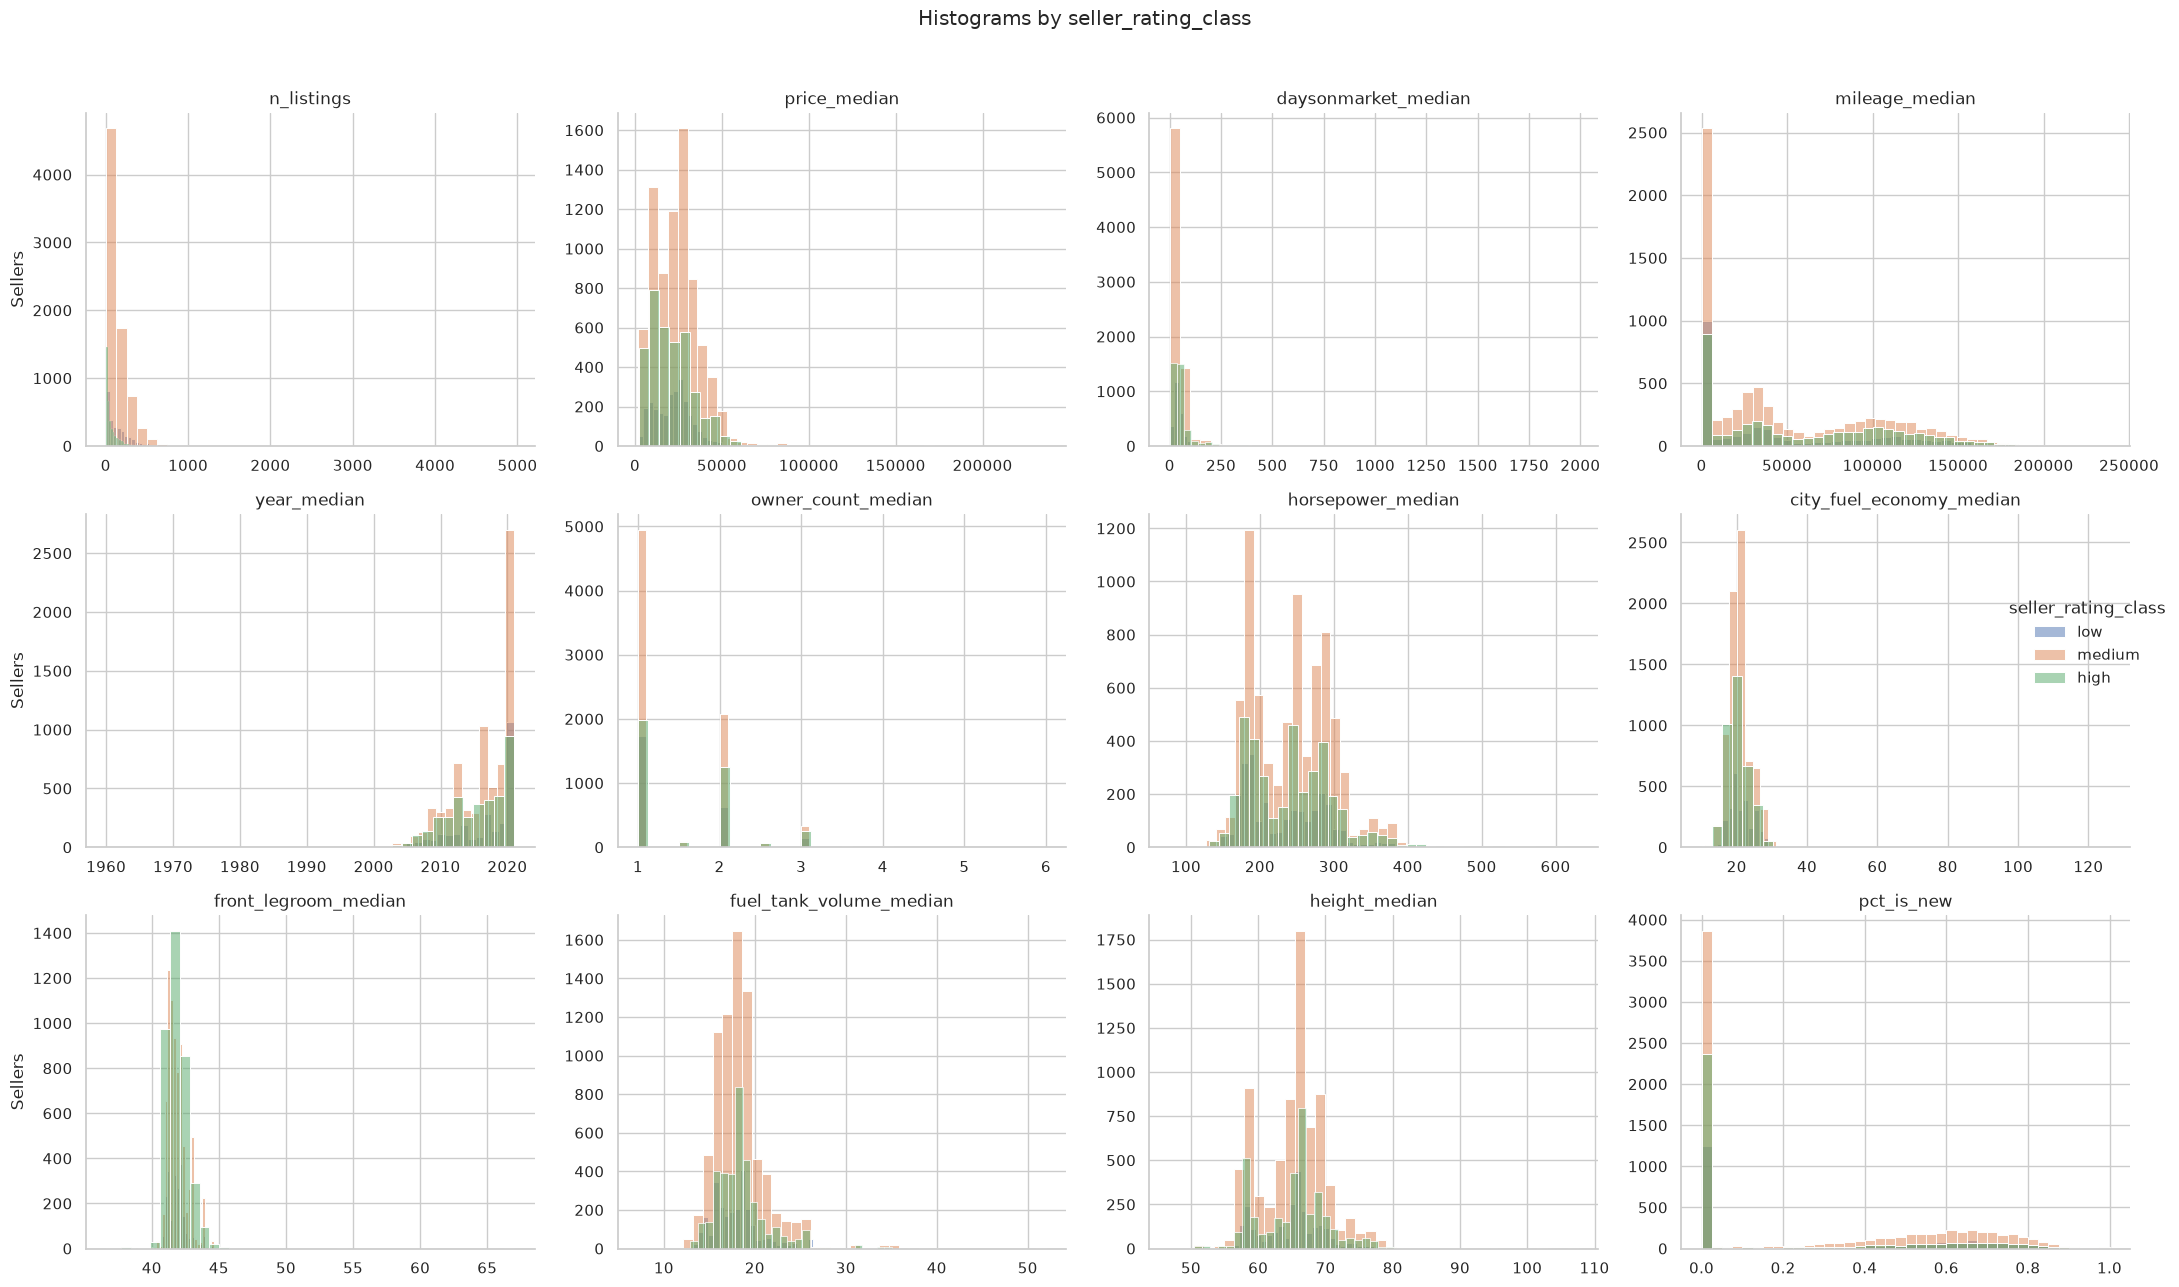

In [19]:
# Same distributions split by the target class
plot_df = df[selected_numeric + [TARGET]].melt(
    id_vars=TARGET, var_name='variable', value_name='value')

g = sns.FacetGrid(
    plot_df, col='variable', col_wrap=4,
    hue=TARGET, hue_order=RATING_ORDER,
    sharex=False, sharey=False, height=4.2, aspect=1.2,
)
g.map_dataframe(
    sns.histplot, x='value', bins=40, multiple='layer', alpha=0.5,
    palette={'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'},
)
g.add_legend(title=TARGET)
g.set_axis_labels('', 'Sellers')
g.set_titles('{col_name}')
g.figure.suptitle('Histograms by seller_rating_class', y=1.02)
plt.tight_layout()
plt.show()


#### Key insights (1.2.2)

- **Bimodality (new vs used)**: `mileage_median` and `pct_is_new` spike at 0 (new cars),
  separated from a broad used-car distribution (30k–120k miles).
- **Lease-return peak**: `vehicle_age_median` has a secondary peak at **3 years**
  (off-lease vehicles) beside the new-car peak at 0.
- **Multimodal engineering**: `engine_displacement_median` clusters around **2.0–2.5 L**
  (4-cylinder) and **3.5–6.0 L** (V6/V8/trucks).
- **Long right tails**: `n_listings`, `price_median`, `savings_amount_median` and
  `daysonmarket_median` have long right tails; the mean and median differ, so quartiles
  are reported alongside the mean (§1.3.2 handles the extremes).
- **No line plots**: there is no per-seller time series, so connecting seller rows with a
  line would imply an order the data do not provide.


### 1.2.3 Distribution via pie chart


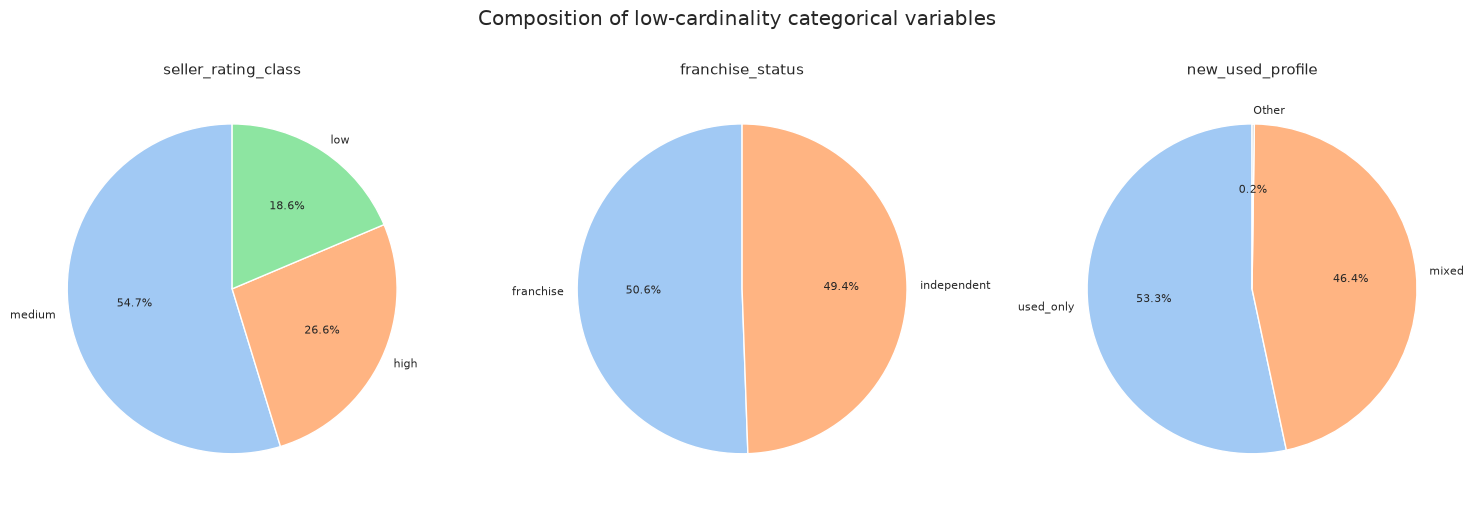

In [20]:
# Pie charts for low-cardinality, part-to-whole variables
pie_cols = ['seller_rating_class', 'franchise_status', 'new_used_profile']
MIN_PCT = 5.0

fig, axes = plt.subplots(1, len(pie_cols), figsize=(5 * len(pie_cols), 5))
axes = np.atleast_1d(axes)

for ax, col in zip(axes, pie_cols):
    vc = df[col].value_counts(dropna=False)
    vc.index = [('missing' if pd.isna(i) else i) for i in vc.index]

    pct = vc / vc.sum() * 100
    keep = vc[pct >= MIN_PCT].copy()
    other = vc[pct < MIN_PCT].sum()
    if other > 0:
        keep.loc['Other'] = other

    labels = list(keep.index)
    colors = list(sns.color_palette('pastel', n_colors=len(labels)))
    if 'Other' in labels:
        colors[labels.index('Other')] = 'lightgray'

    ax.pie(keep.values, labels=labels, colors=colors, autopct='%1.1f%%',
           startangle=90, wedgeprops={'edgecolor': 'white'},
           textprops={'fontsize': 8}, labeldistance=1.08)
    ax.set_title(col, fontsize=11)

plt.suptitle('Composition of low-cardinality categorical variables', y=1.02)
plt.tight_layout()
plt.show()


#### Key insights (1.2.3)

- **Target imbalance**: medium 54.7%, high 26.6%, low 18.6% → use a majority-class
  baseline and, later in classification, a stratified split and Macro-F1.
- **Franchise vs independent** is almost 50/50 (50.6% / 49.4%).
- **Used-only 53.3% vs mixed 46.4%**, while new_only is only 0.2% (31 sellers, grouped
  as "Other" in the pie).
- Literal `unknown` labels (e.g. 1,510 listing colours) are reported separately from
  empty entries and are **not** merged based on automotive assumptions.


### 1.2.4 Distribution via bar chart


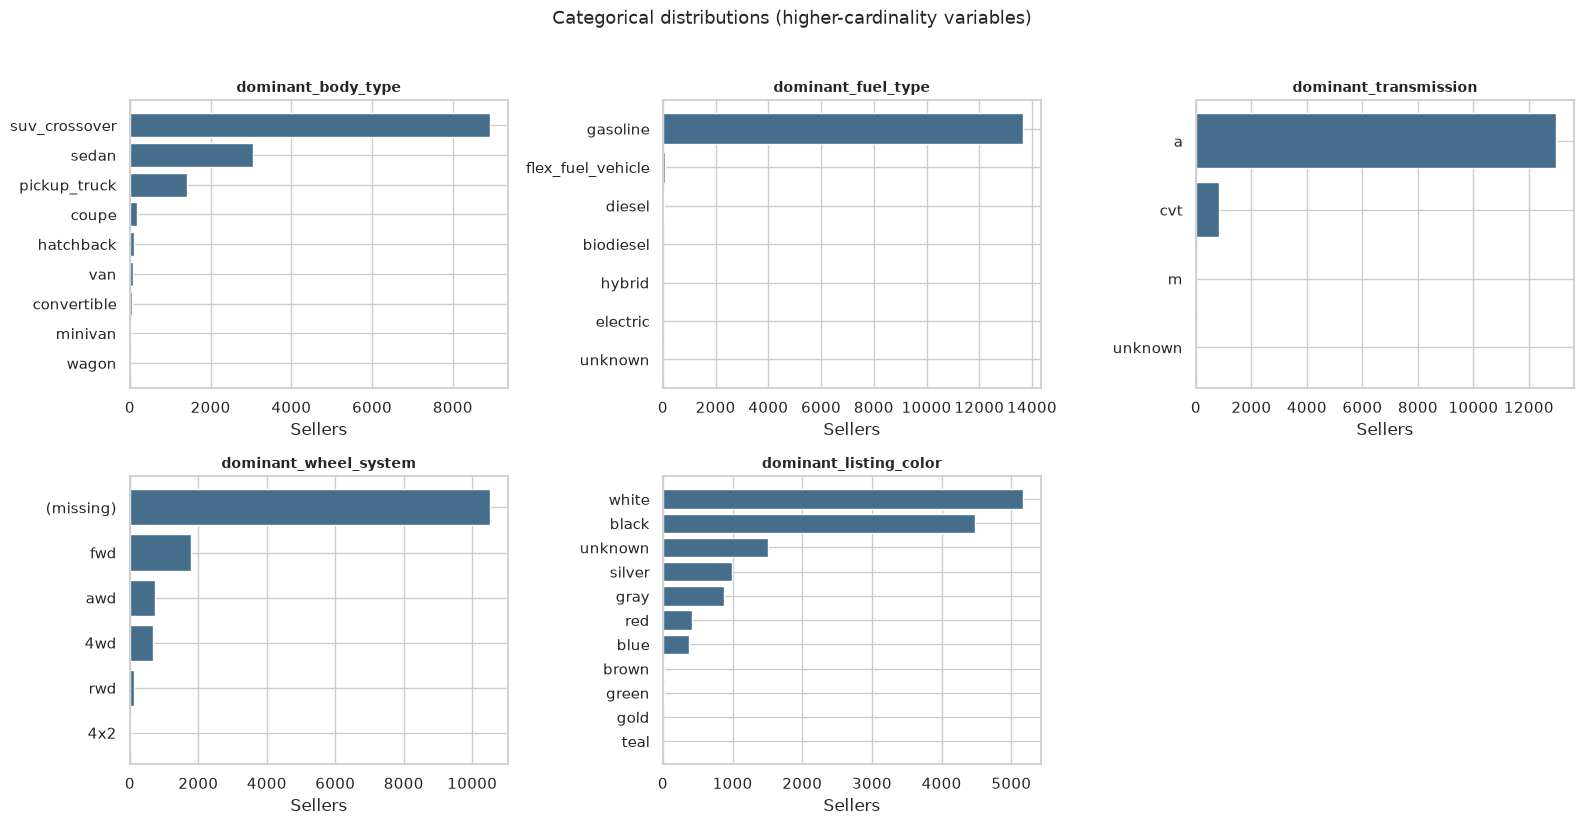

In [24]:
# Bar charts for higher-cardinality / imbalanced categorical variables
bar_cols = ['dominant_body_type', 'dominant_fuel_type', 'dominant_transmission',
            'dominant_wheel_system', 'dominant_listing_color']

ncols = 3
nrows = int(np.ceil(len(bar_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
axes = axes.ravel()

for ax, column in zip(axes, bar_cols):
    values = df[column].fillna('(missing)').value_counts().sort_values()
    ax.barh(values.index, values.values, color='#456e8c')
    ax.set_title(column, fontsize=10, fontweight='bold')
    ax.set_xlabel('Sellers')

for ax in axes[len(bar_cols):]:
    ax.set_visible(False)

fig.suptitle('Categorical distributions (higher-cardinality variables)', fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


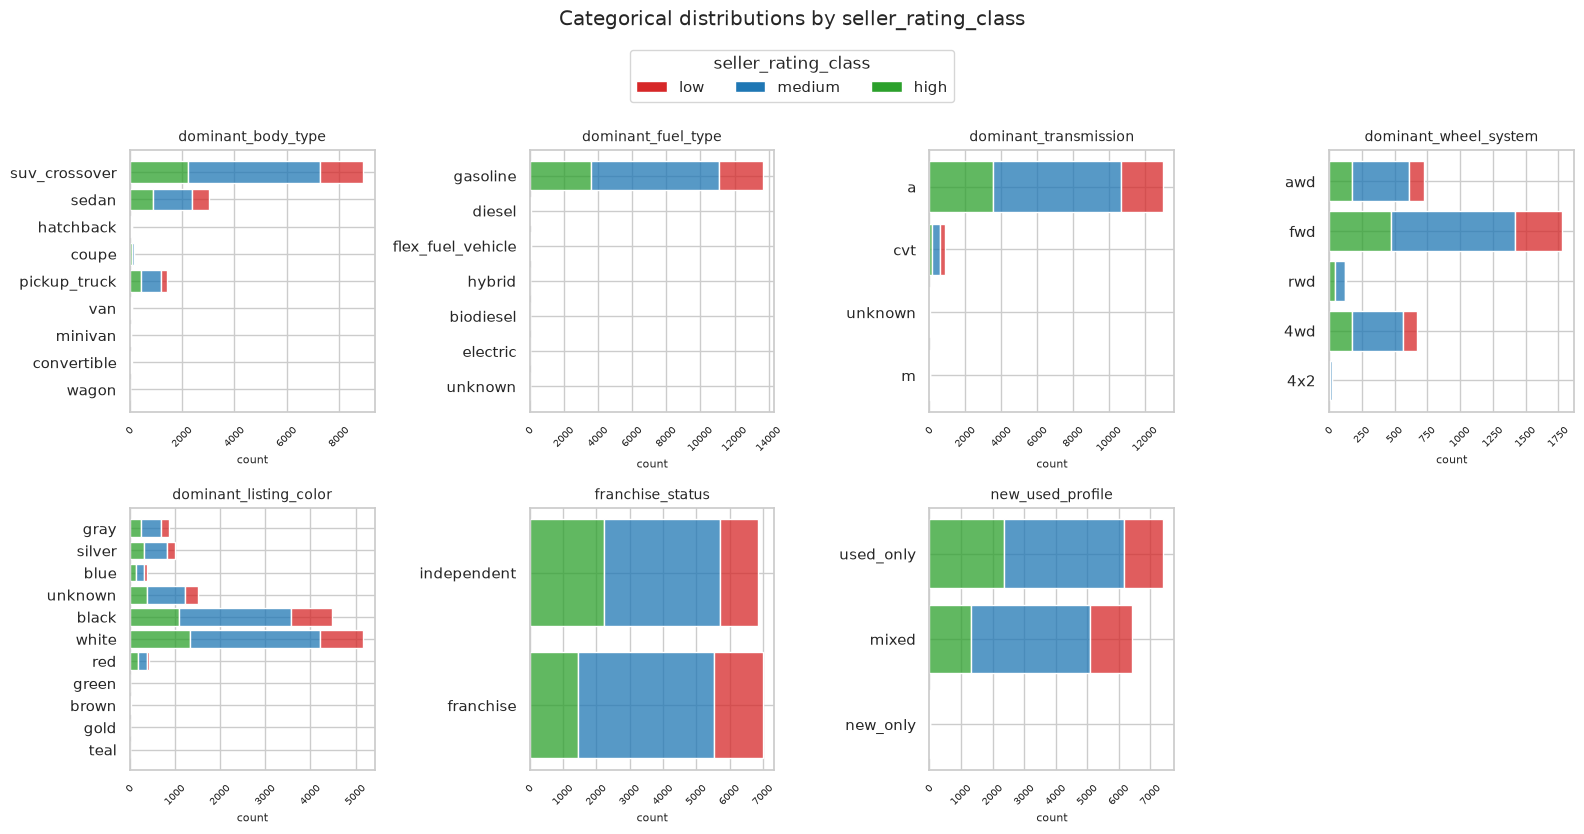

In [22]:
from matplotlib.patches import Patch

# Stacked bars: category counts split by seller_rating_class
palette = {'low': 'tab:red', 'medium': 'tab:blue', 'high': 'tab:green'}
plot_cols = [c for c in categorical_cols if c != TARGET]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, plot_cols):
    sns.histplot(
        data=df, y=col, hue=TARGET, hue_order=RATING_ORDER,
        multiple='stack', palette=palette, ax=ax, shrink=0.8, legend=False,
    )
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.set_ylabel('')
    ax.set_xlabel('count', fontsize=8)

for ax in axes[len(plot_cols):]:
    ax.axis('off')

handles = [Patch(facecolor=palette[k], label=k) for k in RATING_ORDER]
fig.legend(handles=handles, loc='upper center', ncol=3,
           title=TARGET, bbox_to_anchor=(0.5, 1.0))
plt.suptitle('Categorical distributions by seller_rating_class', y=1.04)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


#### Key insights (1.2.4)

- **Category concentration is strong**: SUVs/crossovers 64%, gasoline 99%,
  automatic transmission 94%, and white/black/gray colours ~76%.
- **Wheel system is mostly missing** (76.0%) → not usable for modelling.
- **Rating differs across categories**: independent and used-only sellers have a higher
  share of `high` ratings than franchise/mixed sellers; niche body types (convertible,
  minivan, hatchback) also skew high, but those groups are small.
- **Rare categories** (wagon, electric, new_only, 4x2) should be grouped as `Other`
  before one-hot encoding to avoid sparse columns.


---

**Note:** section 1.2 stops here (descriptive distributions only). Outlier/missing handling
is in §1.3, transformations in §1.4, and correlation-based feature analysis in §1.5.
